**Task 1 - Data Preparation and Feature Engineering**

In [3]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

In [4]:
#Task 1.1 extracting s&p 500 tickers from wikipedia using pandas
url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'

wiki_tables = pd.read_html(url, storage_options={"user-agent": "Mozilla/5.0"})
sp_df = wiki_tables[0]

tickers = sp_df['Symbol'].tolist()
tickers = [t.replace('.', '-') for t in tickers]

retrieval_date = pd.Timestamp.now().strftime('%Y-%m-%d %H:%M')
print('Retrieval date:', retrieval_date)

print('Number of Tickers Extracted:', len(tickers))
sp_df[['Symbol', 'Security', 'GICS Sector']].head(15)

Retrieval date: 2026-11-24 00:21
Number of Tickers Extracted: 503


,Symbol,Security,GICS Sector
0,MMM,3M,Industrials
1,AOS,A. O. Smith,Industrials
2,ABT,Abbott Laboratories,Health Care
3,ABBV,AbbVie,Health Care
4,ACN,Accenture,Information Technology
5,ADBE,Adobe Inc.,Information Technology
6,AMD,Advanced Micro Devices,Information Technology
7,AES,AES Corporation,Utilities
8,AFL,Aflac,Financials
9,A,Agilent Technologies,Health Care


In [5]:
#Task 1.1 Continued Download daily market data via yfinance
# Period: 01-01-2021 to 01-01-2025 (end date exclusive)
start = '2021-01-01'
end = '2025-01-01'

#yfinance chosen
sp_data = yf.download(tickers, start=start, end=end, auto_adjust=False, actions=True)
bench = yf.download('^GSPC', start=start, end=end, auto_adjust=False)

sp_data.to_csv('raw_sp500_daily.csv')
bench.to_csv('raw_gspc_daily.csv')

sp_df.to_csv('sp500_tickers_' + retrieval_date[:10] + '.csv', index=False)
print('yfinance', yf.__version__, '| pandas', pd.__version__)

adj_close = sp_data['Adj Close']
close = sp_data['Close']
volume = sp_data['Volume']
bench_adj = bench['Adj Close'].squeeze()

failed = adj_close.columns[adj_close.isna().all()].tolist()
print('All Tickers that failed to download:', failed)

print('Days and Tickers:', adj_close.shape)
print('Date range:', adj_close.index.min().date(), 'to', adj_close.index.max().date())
adj_close.head()

[*********************100%***********************]  503 of 503 completed
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['SNDK', 'Q', 'HONA', 'VYLR', 'FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
[*********************100%***********************]  1 of 1 completed


yfinance 0.2.66 | pandas 2.2.3
All Tickers that failed to download: ['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']
Days and Tickers: (1005, 503)
Date range: 2021-01-04 to 2024-12-31


Ticker,A,AAPL,ABBV,ABNB,ABT,ACGL,ACN,ADBE,ADI,ADM,...,WY,WYNN,XEL,XOM,XYL,XYZ,YUM,ZBH,ZBRA,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-04,114.009117,125.537132,84.219147,139.149994,97.269707,33.186359,232.029327,485.339996,132.622635,42.189495,...,26.124489,102.852104,54.757389,33.042770,93.015892,221.160004,95.016190,141.603363,378.130005,152.952042
2021-01-05,114.941261,127.089188,85.090027,148.300003,98.473198,33.319485,233.350250,485.690002,134.993179,43.010094,...,26.371325,106.017525,54.223656,34.635185,92.903938,229.750000,95.025177,144.053436,380.570007,154.017883
2021-01-06,118.093239,122.811203,84.354965,142.770004,98.268158,34.783871,235.901642,466.309998,135.601730,44.752834,...,26.506687,106.652519,55.424561,35.518990,96.822739,226.889999,95.545967,148.158371,394.820007,156.280533
2021-01-07,121.235596,127.001923,85.257790,151.270004,99.222046,34.460564,238.127289,477.739990,141.332733,44.355217,...,26.761486,105.594177,54.340420,35.797657,101.217422,239.479996,94.818649,147.280090,409.100006,156.140274
2021-01-08,122.100464,128.098099,85.705193,149.770004,99.498421,34.650742,238.995834,485.100006,142.359070,44.473667,...,26.578352,104.901436,54.840775,36.195759,100.191055,241.449997,96.210411,146.956451,405.470001,157.178070


In [6]:
#Task 1.2: Validation checks
print('Duplicate dates:', adj_close.index.duplicated().sum())
print('Duplicate dates:', bench_adj.index.duplicated().sum())
print('Non positive adjusted prices:', (adj_close <= 0).sum().sum())
print('Non positive close prices:', (close <= 0).sum().sum())
print('Negative volumes:', (volume < 0).sum().sum())
print('Zero volumes:', (volume == 0).sum().sum())

print('Dates in shares but not benchmark:', len(adj_close.index.difference(bench_adj.index)))
print('Dates in benchmark but not shares:', len(bench_adj.index.difference(adj_close.index)))

print('Missing adjusted prices:', adj_close.isna().sum().sum())
print('Missing close prices:', close.isna().sum().sum())
print('Missing volumes:', volume.isna().sum().sum())
print('Missing benchmark prices:', bench_adj.isna().sum())

splits = sp_data['Stock Splits']
split_tickers = splits.columns[(splits > 0).any()].tolist()
print('Shares with a stock split in the period:', len(split_tickers))

dividends = sp_data['Dividends']
print('Shares paying dividends in the period:', (dividends > 0).any().sum())

close_move = close.pct_change(fill_method=None).abs()
print('Largest Close move on a split day:', round(close_move.where(splits > 0).max().max() * 100, 1), '%')

daily_move = adj_close.pct_change(fill_method=None).abs()
big_moves = (daily_move > 0.4).sum()
print('Shares with a one day move above 40%:', big_moves[big_moves > 0].to_dict())

first_date = adj_close.apply(lambda s: s.first_valid_index())
print('Shares starting more than 10 days after the first date:', (first_date > first_date.min() + pd.Timedelta(days=10)).sum())

Duplicate dates: 0
Duplicate dates: 0
Non positive adjusted prices: 0
Non positive close prices: 0
Negative volumes: 0
Zero volumes: 451
Dates in shares but not benchmark: 0
Dates in benchmark but not shares: 0
Missing adjusted prices: 9211
Missing close prices: 9211
Missing volumes: 9211
Missing benchmark prices: 0
Shares with a stock split in the period: 53
Shares paying dividends in the period: 399
Largest Close move on a split day: 7.7 %
Shares with a one day move above 40%: {'APP': 1, 'BE': 1, 'CVNA': 5, 'DXCM': 1, 'GL': 1, 'HOOD': 1, 'RDDT': 1}
Shares starting more than 10 days after the first date: 10


In [7]:
#Task 1.2: Clean the data
print('Before cleaning:', adj_close.shape)

adj_close = adj_close[~adj_close.index.duplicated()]
close = close[~close.index.duplicated()]
volume = volume[~volume.index.duplicated()]
bench_adj = bench_adj[~bench_adj.index.duplicated()]

adj_close = adj_close.where(adj_close > 0)
close = close.where(close > 0)
volume = volume.where(volume > 0)
bench_adj = bench_adj.where(bench_adj > 0)

coverage = adj_close.notna().mean()
exclusions = coverage[coverage < 0.80].reset_index()
exclusions.columns = ['Ticker', 'Reason']
exclusions['Reason'] = 'Less than 80% of dates available (' + (coverage[coverage < 0.80].values * 100).round(1).astype(str) + '%)'
exclusions['Stage'] = '1.2 Validation'

kept = coverage[coverage >= 0.80].index.tolist()
adj_close, close, volume = adj_close[kept], close[kept], volume[kept]

print('After cleaning:', adj_close.shape)
print('Tickers removed:', len(exclusions))
exclusions.head(10)

Before cleaning: (1005, 503)
After cleaning: (1005, 492)
Tickers removed: 11


,Ticker,Reason,Stage
0,CEG,Less than 80% of dates available (73.8%),1.2 Validation
1,FDXF,Less than 80% of dates available (0.0%),1.2 Validation
2,GEHC,Less than 80% of dates available (51.0%),1.2 Validation
3,GEV,Less than 80% of dates available (19.2%),1.2 Validation
4,HONA,Less than 80% of dates available (0.0%),1.2 Validation
5,Q,Less than 80% of dates available (0.0%),1.2 Validation
6,RDDT,Less than 80% of dates available (19.6%),1.2 Validation
7,SNDK,Less than 80% of dates available (0.0%),1.2 Validation
8,SOLV,Less than 80% of dates available (19.3%),1.2 Validation
9,VLTO,Less than 80% of dates available (31.1%),1.2 Validation


In [8]:
#Task 1.3 Weekly returns using Friday ending weeks
weekly_prices = adj_close.resample('W-FRI').last()
weekly_bench = bench_adj.resample('W-FRI').last()

#fill_method=None stops pandas filling gaps
weekly_returns = weekly_prices.pct_change(fill_method=None)
bench_returns = weekly_bench.pct_change(fill_method=None)

week_monday = weekly_returns.index - pd.Timedelta(days=4)
complete_week = (week_monday >= pd.Timestamp(start)) & (weekly_returns.index < pd.Timestamp(end))
weekly_returns = weekly_returns[complete_week]
bench_returns = bench_returns[complete_week]

common_weeks = bench_returns.dropna().index
weekly_returns = weekly_returns.loc[common_weeks]
bench_returns = bench_returns.loc[common_weeks]

print('Aligned weekly observations (benchmark):', len(common_weeks))
print('First & Last week:', common_weeks.min().date(), common_weeks.max().date())

mean_return = weekly_returns.mean()

n_weeks = weekly_returns.notna().sum()

pd.DataFrame({'Mean weekly return': mean_return, 'Weekly observations': n_weeks}).describe()

Aligned weekly observations (benchmark): 207
First & Last week: 2021-01-15 2024-12-27


,Mean weekly return,Weekly observations
count,492.000000,492.000000
mean,0.002900,206.873984
std,0.002697,1.595683
min,-0.004468,178.000000
25%,0.001204,207.000000
50%,0.002668,207.000000
75%,0.004264,207.000000
max,0.017772,207.000000


In [9]:
#Task 1.3.2 Weekly beta
#Only weeks where both the share and benchmark have a return are used
beta = {}
beta_weeks = {}
for t in weekly_returns.columns:
    pair = pd.concat([weekly_returns[t], bench_returns], axis=1).dropna()
    beta[t] = pair.iloc[:, 0].cov(pair.iloc[:, 1]) / pair.iloc[:, 1].var()
    beta_weeks[t] = len(pair)
beta = pd.Series(beta)
beta_weeks = pd.Series(beta_weeks)

t0 = weekly_returns.columns[0]
pair0 = pd.concat([weekly_returns[t0], bench_returns], axis=1).dropna()
print('Beta check for', t0, ':', round(beta[t0], 4), 'vs', round(np.polyfit(pair0.iloc[:, 1], pair0.iloc[:, 0], 1)[0], 4))
print('Aligned weeks used per share (min, max):', beta_weeks.min(), beta_weeks.max())
pd.DataFrame({'Weekly Beta': beta, 'Aligned Weeks': beta_weeks}).describe()

Beta check for A : 1.0747 vs 1.0747
Aligned weeks used per share (min, max): 178 207


,Weekly Beta,Aligned Weeks
count,492.000000,492.000000
mean,0.982445,206.873984
std,0.422073,1.595683
min,0.055453,178.000000
25%,0.670048,207.000000
50%,0.954712,207.000000
75%,1.183847,207.000000
max,3.778560,207.000000


In [10]:
#Task 1.4 RFM calculations

px, vol = close, volume

obs_date = (px.notna() & vol.notna()).all(axis=1).loc[lambda s: s].index.max()
px, vol = px.loc[:obs_date], vol.loc[:obs_date]
window = vol.index[-60:]

baseline = vol.apply(lambda s: s.dropna().rolling(20).mean().shift(1))
event = vol.gt(2 * baseline)

recency = pd.Series({
    ticker: (obs_date - event[ticker][event[ticker]].index[-1]).days
            if event[ticker].any() else np.nan
    for ticker in event.columns
}, name='Recency_Days')

enough = (vol.loc[window].notna() & baseline.loc[window].notna()).all(axis=0).rename('Enough_History')

frequency = event.loc[window].sum(axis=0).where(enough).rename('Frequency_Days')
valid_sessions = vol.notna().sum(axis=0).rename('Valid_Sessions')
monetary = (px.loc[window] * vol.loc[window]).sum(axis=0).where(enough).rename('Monetary_USD')

rfm = pd.concat([recency, frequency, valid_sessions, monetary, enough], axis=1)

rfm['Exclusion_Reason'] = np.select(
    [rfm['Recency_Days'].isna(), ~rfm['Enough_History']],
    ['No high volume event in study history', 'Insufficient 20/60 session history'],
    default='')
dropped = rfm[rfm['Exclusion_Reason'] != '']
exclusions = pd.concat([exclusions, pd.DataFrame({'Ticker': dropped.index,
                        'Reason': dropped['Exclusion_Reason'].values, 'Stage': '1.4 RFM'})],
                       ignore_index=True)
rfm_clean = rfm.loc[rfm['Exclusion_Reason'] == '', ['Recency_Days', 'Frequency_Days', 'Monetary_USD']]

rfm.to_csv(f'rfm_{obs_date.date()}.csv')
exclusions.to_csv('exclusion_log.csv', index=False)

ex = 'ABBV' if 'ABBV' in rfm_clean.index else rfm_clean.index[0]
s = vol[ex].dropna()
manual = s.loc[:obs_date].iloc[-21:-1].mean()

print('Observations date:', obs_date.date(), '| 60 session window starts:', window[0].date())
print('Shares with RFM:', len(rfm_clean), '| excluded at 1.4:', len(dropped))
print('Baseline for', ex, ':', round(manual), 'vs', round(baseline.loc[obs_date, ex]))
rfm_clean.describe()

Observations date: 2024-12-31 | 60 session window starts: 2024-10-07
Shares with RFM: 492 | excluded at 1.4: 0
Baseline for ABBV : 5890265 vs 5890265


,Recency_Days,Frequency_Days,Monetary_USD
count,492.000000,492.000000,4.920000e+02
mean,20.493902,2.995935,3.974218e+10
std,21.303977,1.328055,1.286397e+11
min,4.000000,0.000000,1.297483e+09
25%,11.000000,2.000000,1.025241e+10
50%,11.000000,3.000000,1.679667e+10
75%,18.000000,4.000000,3.253548e+10
max,222.000000,8.000000,1.847697e+12


In [11]:
#Task 1.5 common valid share set all five features
features = pd.concat([mean_return.rename('Mean_Weekly_Return'),
                      beta.rename('Weekly_Beta'),
                      rfm_clean], axis=1)
common = features.dropna()
common.to_csv('feature_table.csv')

print('Tickers from Wikipedia:', len(tickers))
print('After 1.2 validation:', len(kept))
print('With RFM values (1.4):', len(rfm_clean))
print('Common valid share set:', len(common))
print(exclusions.groupby(['Stage', 'Reason']).size())

#example
last = event[ex][event[ex]].index[-1]
window_events = event.loc[window, ex][event.loc[window, ex]].index
print(f'\nOne example: {ex}')
print(f'R = {obs_date.date()} - {last.date()} = {(obs_date - last).days} calendar days')
print(f'F = {len(window_events)} qualifying days in the 60 sessions:', [d.date() for d in window_events])
print(f"M = sum of Close x Volume over 60 sessions = ${rfm_clean.loc[ex, 'Monetary_USD'] / 1e9:.2f} billion")

summary = common.describe().T
summary['skew'] = common.skew()
summary.round(4)

Tickers from Wikipedia: 503
After 1.2 validation: 492
With RFM values (1.4): 492
Common valid share set: 492
Stage           Reason                                  
1.2 Validation  Less than 80% of dates available (0.0%)     5
                Less than 80% of dates available (19.2%)    1
                Less than 80% of dates available (19.3%)    1
                Less than 80% of dates available (19.6%)    1
                Less than 80% of dates available (31.1%)    1
                Less than 80% of dates available (51.0%)    1
                Less than 80% of dates available (73.8%)    1
dtype: int64

One example: ABBV
R = 2024-12-31 - 2024-12-20 = 11 calendar days
F = 3 qualifying days in the 60 sessions: [datetime.date(2024, 10, 30), datetime.date(2024, 11, 11), datetime.date(2024, 12, 20)]
M = sum of Close x Volume over 60 sessions = $68.37 billion


,count,mean,std,min,25%,50%,75%,max,skew
Mean_Weekly_Return,492.0,2.900000e-03,2.700000e-03,-4.500000e-03,1.200000e-03,2.700000e-03,4.300000e-03,1.780000e-02,0.9372
Weekly_Beta,492.0,9.824000e-01,4.221000e-01,5.550000e-02,6.700000e-01,9.547000e-01,1.183800e+00,3.778600e+00,1.2473
Recency_Days,492.0,2.049390e+01,2.130400e+01,4.000000e+00,1.100000e+01,1.100000e+01,1.800000e+01,2.220000e+02,3.6190
Frequency_Days,492.0,2.995900e+00,1.328100e+00,0.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,8.000000e+00,0.4161
Monetary_USD,492.0,3.974218e+10,1.286397e+11,1.297483e+09,1.025241e+10,1.679667e+10,3.253548e+10,1.847697e+12,11.6729


**Task 2 - Stock Segmentation and Sensitivity Analysis**

In [12]:
#Task 2.1 Feature preparation

#Two feature matrices
rr = common[['Mean_Weekly_Return', 'Weekly_Beta']].copy()
act = common[['Recency_Days', 'Frequency_Days', 'Monetary_USD']].copy()

raw = pd.concat([rr, act], axis=1)
q1, q3 = raw.quantile(0.25), raw.quantile(0.75)
outliers = ((raw < q1 - 1.5 * (q3 - q1)) | (raw > q3 + 1.5 * (q3 - q1))).sum()
print(pd.DataFrame({'Skew': raw.skew().round(2), 'Outliers': outliers}))

act['Monetary_USD'] = np.log1p(act['Monetary_USD'])
act['Recency_Days'] = np.log1p(act['Recency_Days'])
print('Skew after log1p:', act.skew().round(2).to_dict())

X_rr = pd.DataFrame(StandardScaler().fit_transform(rr), index=rr.index, columns=rr.columns)
X_act = pd.DataFrame(StandardScaler().fit_transform(act), index=act.index, columns=act.columns)
X_act.describe().round(2)

                     Skew  Outliers
Mean_Weekly_Return   0.94        16
Weekly_Beta          1.25        12
Recency_Days         3.62        96
Frequency_Days       0.42         2
Monetary_USD        11.67        47
Skew after log1p: {'Recency_Days': 1.56, 'Frequency_Days': 0.42, 'Monetary_USD': 1.07}


,Recency_Days,Frequency_Days,Monetary_USD
count,492.00,492.00,492.00
mean,-0.00,-0.00,0.00
std,1.00,1.00,1.00
min,-1.95,-2.26,-2.86
25%,-0.53,-0.75,-0.68
50%,-0.53,0.00,-0.15
75%,0.21,0.76,0.54
max,4.20,3.77,4.82


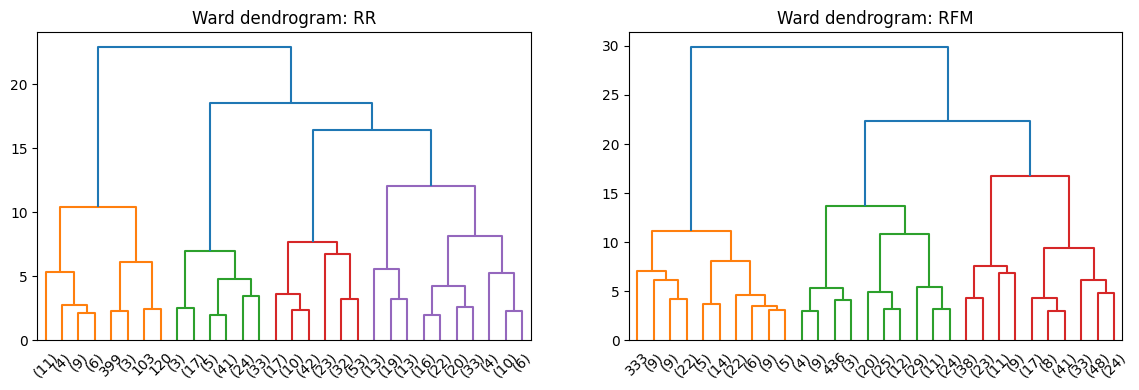

,Matrix,k,Silhouette,Sizes
0,RR,2,0.509,"[456, 36]"
1,RR,3,0.263,"[333, 123, 36]"
2,RR,4,0.295,"[177, 156, 123, 36]"
3,RR,5,0.319,"[177, 123, 111, 45, 36]"
4,RR,6,0.324,"[177, 123, 111, 45, 30, 6]"
5,RR,7,0.306,"[177, 123, 91, 45, 30, 20, 6]"
6,RR,8,0.294,"[123, 108, 91, 69, 45, 30, 20, 6]"
7,RFM,2,0.398,"[390, 102]"
8,RFM,3,0.325,"[252, 138, 102]"
9,RFM,4,0.302,"[171, 138, 102, 81]"


In [13]:
# Task 2.2 Agglomerative clustering (Ward linkage, Euclidean distance)

matrices = {'RR': X_rr, 'RFM': X_act}

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (name, X) in zip(axes, matrices.items()):
    dendrogram(linkage(X, method='ward'), truncate_mode='lastp', p=30, ax=ax)
    ax.set_title(f'Ward dendrogram: {name}')
plt.show()

rows = []
for name, X in matrices.items():
    for k in range(2, 9):
        labels = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X)
        rows.append({'Matrix': name, 'k': k, 'Silhouette': round(silhouette_score(X, labels), 3),
                     'Sizes': sorted(np.bincount(labels), reverse=True)})
ward_results = pd.DataFrame(rows)
ward_results

In [14]:
# fit the chosen k and profile clusters in original units
K_WARD = {'RR': 5, 'RFM': 3}

for name, X in matrices.items():
    common[f'Ward_{name}'] = AgglomerativeClustering(n_clusters=K_WARD[name], linkage='ward').fit_predict(X)

print(common.groupby('Ward_RR')[['Mean_Weekly_Return', 'Weekly_Beta']].median().round(4))
print(common.groupby('Ward_RFM')[['Recency_Days', 'Frequency_Days', 'Monetary_USD']].median().round(1))

         Mean_Weekly_Return  Weekly_Beta
Ward_RR                                 
0                    0.0080       1.4445
1                    0.0008       1.0307
2                    0.0020       0.5187
3                    0.0041       0.9994
4                    0.0026       1.5012
          Recency_Days  Frequency_Days  Monetary_USD
Ward_RFM                                            
0                 11.0             3.0  1.117761e+10
1                 49.5             2.0  2.225004e+10
2                 11.0             3.0  4.066914e+10


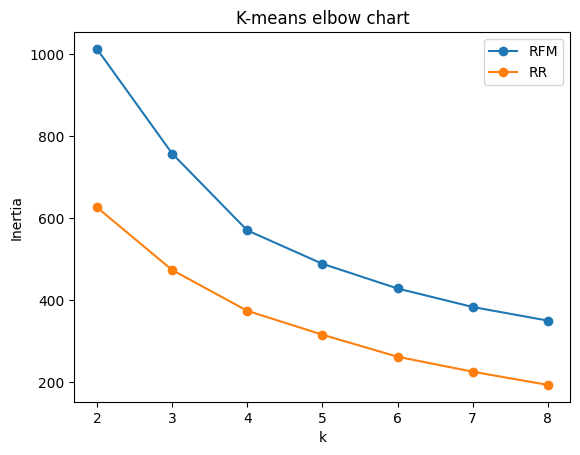

,Matrix,k,Silhouette,Inertia,Sizes
0,RR,2,0.389,626.7,"[345, 147]"
1,RR,3,0.321,473.8,"[204, 166, 122]"
2,RR,4,0.325,374.1,"[169, 149, 132, 42]"
3,RR,5,0.337,315.8,"[174, 131, 109, 51, 27]"
4,RR,6,0.335,261.9,"[159, 119, 110, 56, 41, 7]"
5,RR,7,0.333,225.4,"[146, 86, 82, 74, 49, 48, 7]"
6,RR,8,0.355,193.1,"[140, 80, 76, 76, 44, 40, 29, 7]"
7,RFM,2,0.415,1013.6,"[389, 103]"
8,RFM,3,0.340,758.2,"[259, 140, 93]"
9,RFM,4,0.360,570.5,"[197, 120, 91, 84]"


In [15]:
#Task 2.3 K-means clustering

rows = []
for name, X in matrices.items():
    for k in range(2, 9):
        km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
        rows.append({'Matrix': name, 'k': k, 'Silhouette': round(silhouette_score(X, km.labels_), 3),
                     'Inertia': round(km.inertia_, 1), 'Sizes': sorted(np.bincount(km.labels_), reverse=True)})
km_results = pd.DataFrame(rows)

#elbow chart of inertia for each matrix
for name, res in km_results.groupby('Matrix'):
    plt.plot(res['k'], res['Inertia'], marker='o', label=name)
plt.xlabel('k'); plt.ylabel('Inertia'); plt.title('K-means elbow chart'); plt.legend(); plt.show()
km_results

In [17]:
# fit the chosen k and profile clusters in original units
K_KM = {'RR': 5, 'RFM': 3}

for name, X in matrices.items():
    common[f'KMeans_{name}'] = KMeans(n_clusters=K_KM[name], random_state=42, n_init=10).fit_predict(X)

print(common.groupby('KMeans_RR')[['Mean_Weekly_Return', 'Weekly_Beta']].median().round(4))
print(common.groupby('KMeans_RFM')[['Recency_Days', 'Frequency_Days', 'Monetary_USD']].median().round(1))

           Mean_Weekly_Return  Weekly_Beta
KMeans_RR                                 
0                      0.0042       0.9886
1                      0.0085       1.5440
2                      0.0008       1.0358
3                      0.0019       0.5342
4                      0.0027       1.5535
            Recency_Days  Frequency_Days  Monetary_USD
KMeans_RFM                                            
0                   11.0             3.0  1.120162e+10
1                   11.0             3.0  4.315921e+10
2                   53.0             2.0  2.124212e+10



Ward_RR profiles (medians, original units)
          Mean_Weekly_Return  Weekly_Beta  Shares
Ward_RR                                         
0                    0.0080       1.4445      36
1                    0.0008       1.0307     111
2                    0.0020       0.5187     123
3                    0.0041       0.9994     177
4                    0.0026       1.5012      45

KMeans_RR profiles (medians, original units)
            Mean_Weekly_Return  Weekly_Beta  Shares
KMeans_RR                                         
0                      0.0042       0.9886     174
1                      0.0085       1.5440      27
2                      0.0008       1.0358     109
3                      0.0019       0.5342     131
4                      0.0027       1.5535      51

Ward_RFM profiles (medians, original units)
           Recency_Days  Frequency_Days  Monetary_USD  Shares
Ward_RFM                                                    
0                 11.0             3.0  

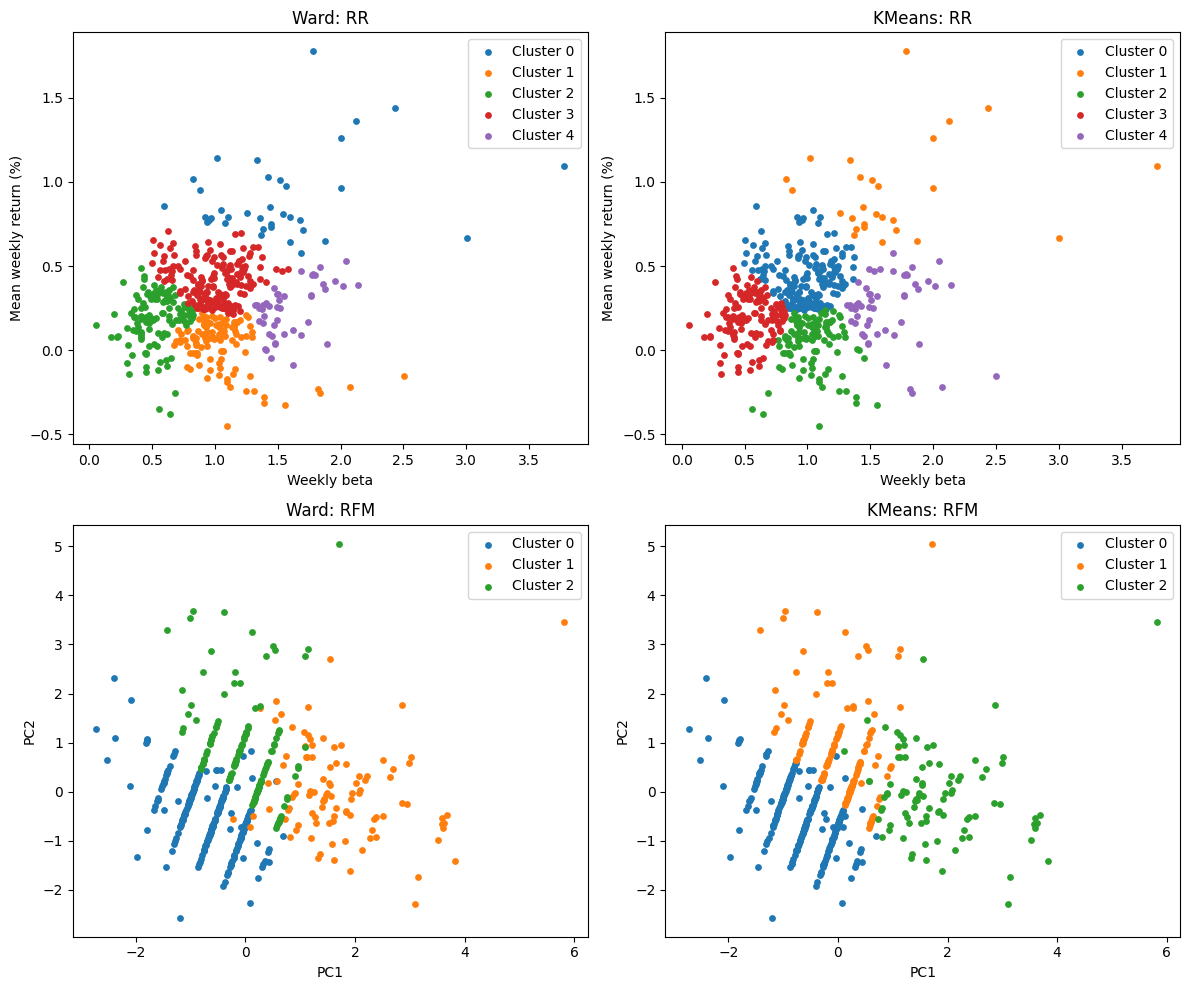


RR: adjusted Rand index Ward vs K-means = 0.828
K-means    0   1   2    3   4
Ward                         
0          8  27   0    0   1
1          0   0  99    8   4
2          0   0   3  120   0
3        166   0   4    3   4
4          0   0   3    0  42

RFM: adjusted Rand index Ward vs K-means = 0.903
K-means    0    1   2
Ward                 
0        250    0   2
1          4    7  91
2          5  133   0


In [18]:
#Task 2.4 Cluster profiles and algorithm comparison

feats = {'RR': ['Mean_Weekly_Return', 'Weekly_Beta'],
         'RFM': ['Recency_Days', 'Frequency_Days', 'Monetary_USD']}

for name in ['RR', 'RFM']:
    for method in ['Ward', 'KMeans']:
        col = f'{method}_{name}'
        prof = common.groupby(col)[feats[name]].median()
        prof['Shares'] = common[col].value_counts()
        print(f'\n{col} profiles (medians, original units)\n', prof.round(4))

pca = PCA(n_components=2, random_state=42)
rfm_2d = pca.fit_transform(X_act)
print('\nPCA variance explained (PC1, PC2):', pca.explained_variance_ratio_.round(3),
      '| total:', pca.explained_variance_ratio_.sum().round(3))

coords = {'RR': (common['Weekly_Beta'], common['Mean_Weekly_Return'] * 100, 'Weekly beta', 'Mean weekly return (%)'),
          'RFM': (rfm_2d[:, 0], rfm_2d[:, 1], 'PC1', 'PC2')}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for i, name in enumerate(['RR', 'RFM']):
    x, y, xl, yl = coords[name]
    for j, method in enumerate(['Ward', 'KMeans']):
        ax, col = axes[i, j], f'{method}_{name}'
        for c in sorted(common[col].unique()):
            m = (common[col] == c).values
            ax.scatter(np.asarray(x)[m], np.asarray(y)[m], s=15, label=f'Cluster {c}')
        ax.set_title(f'{method}: {name}'); ax.set_xlabel(xl); ax.set_ylabel(yl); ax.legend()
plt.tight_layout(); plt.show()

#compare the two algorithms on the same shares
for name in ['RR', 'RFM']:
    ari = adjusted_rand_score(common[f'Ward_{name}'], common[f'KMeans_{name}'])
    print(f'\n{name}: adjusted Rand index Ward vs K-means = {ari:.3f}')
    print(pd.crosstab(common[f'Ward_{name}'], common[f'KMeans_{name}'], rownames=['Ward'], colnames=['K-means']))

In [19]:
# Task 2.5.1 Correlation analysis, log1p(M)
corr_data = pd.DataFrame({'R': common['Recency_Days'],
                          'F': common['Frequency_Days'],
                          'log1p(M)': np.log1p(common['Monetary_USD'])})
print('Correlation matrix (Pearson):')
corr_data.corr().round(3)

Correlation matrix (Pearson):


,R,F,log1p(M)
R,1.000,-0.339,0.161
F,-0.339,1.000,0.023
log1p(M),0.161,0.023,1.000


In [20]:
# Task 2.5.2 Removal of Monetary
X_rf = pd.DataFrame(StandardScaler().fit_transform(act[['Recency_Days', 'Frequency_Days']]),
                    index=act.index, columns=['Recency_Days', 'Frequency_Days'])
common['Ward_RF'] = AgglomerativeClustering(n_clusters=K_WARD['RFM'], linkage='ward').fit_predict(X_rf)

print('Adjusted Rand index, Ward RFM vs Ward RF:', round(adjusted_rand_score(common['Ward_RFM'], common['Ward_RF']), 3))
print(pd.crosstab(common['Ward_RFM'], common['Ward_RF'], rownames=['With M'], colnames=['Without M']))

for col in ['Ward_RFM', 'Ward_RF']:
    prof = common.groupby(col)[['Recency_Days', 'Frequency_Days', 'Monetary_USD']].median()
    prof['Monetary_USD'] = (prof['Monetary_USD'] / 1e9).round(1)
    prof['Shares'] = common[col].value_counts()
    print(f'\n{col} profiles (medians; Monetary in $bn)\n', prof)

Adjusted Rand index, Ward RFM vs Ward RF: 0.298
Without M   0    1   2
With M                
0          11  175  66
1          95    7   0
2           7   72  59

Ward_RFM profiles (medians; Monetary in $bn)
           Recency_Days  Frequency_Days  Monetary_USD  Shares
Ward_RFM                                                    
0                 11.0             3.0          11.2     252
1                 49.5             2.0          22.3     102
2                 11.0             3.0          40.7     138

Ward_RF profiles (medians; Monetary in $bn)
          Recency_Days  Frequency_Days  Monetary_USD  Shares
Ward_RF                                                    
0                46.0             2.0          21.1     113
1                11.0             4.0          14.7     254
2                11.0             2.0          17.7     125



Ward_RR profiles (medians; return in %, Monetary in $bn)
          Mean_Weekly_Return  Weekly_Beta  Recency_Days  Frequency_Days  \
Ward_RR                                                                  
0                      0.80         1.44          11.0             3.0   
1                      0.08         1.03          11.0             3.0   
2                      0.20         0.52          11.0             3.0   
3                      0.41         1.00          11.0             3.0   
4                      0.26         1.50          11.0             3.0   

         Monetary_USD  Shares  
Ward_RR                        
0                27.0      36  
1                13.6     111  
2                14.6     123  
3                18.2     177  
4                29.1      45  

Ward_RFM profiles (medians; return in %, Monetary in $bn)
           Mean_Weekly_Return  Weekly_Beta  Recency_Days  Frequency_Days  \
Ward_RFM                                                       

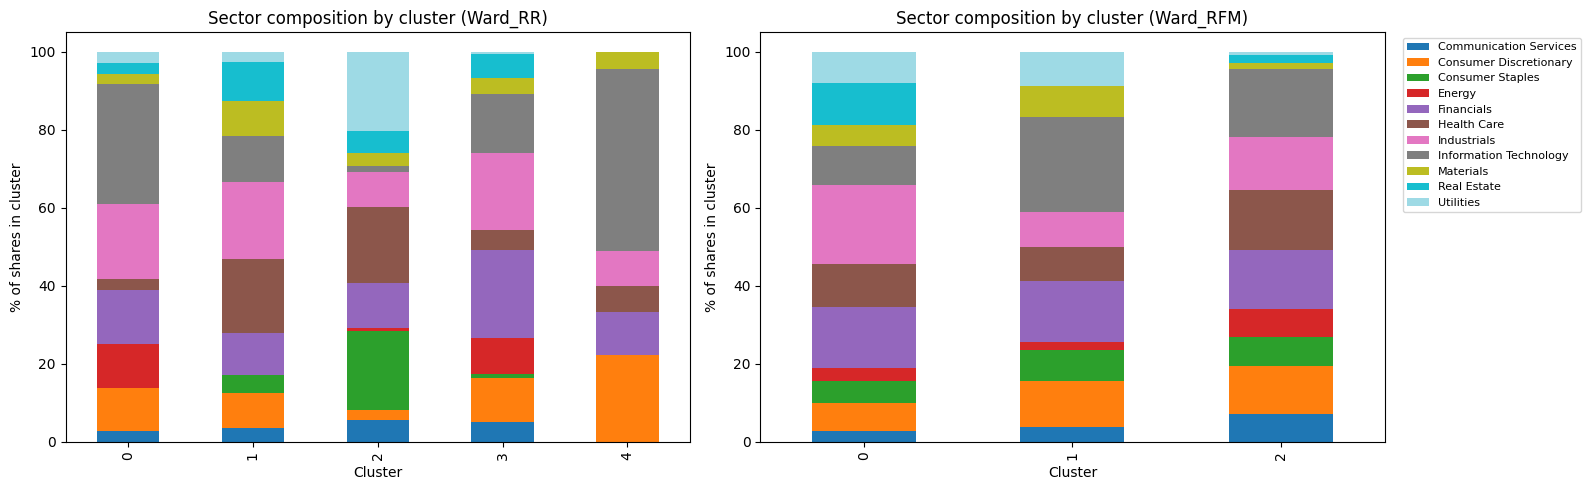


Adjusted Rand index, Ward RR vs Ward RFM: 0.015


RFM cluster,0,1,2
Return/beta cluster,,,
0,11,10,15
1,68,23,20
2,66,24,33
3,91,33,53
4,16,12,17


In [21]:
# Task 3.2.1 Cluster profiles and sector composition
sector = sp_df.set_index(sp_df['Symbol'].str.replace('.', '-', regex=False))['GICS Sector']
common['Sector'] = sector.reindex(common.index)

for col in ['Ward_RR', 'Ward_RFM']:
    prof = common.groupby(col)[['Mean_Weekly_Return', 'Weekly_Beta', 'Recency_Days', 'Frequency_Days', 'Monetary_USD']].median()
    prof['Mean_Weekly_Return'] = (prof['Mean_Weekly_Return'] * 100).round(2)
    prof['Monetary_USD'] = (prof['Monetary_USD'] / 1e9).round(1)
    prof['Shares'] = common[col].value_counts()
    print(f'\n{col} profiles (medians; return in %, Monetary in $bn)\n', prof.round(2))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, col in zip(axes, ['Ward_RR', 'Ward_RFM']):
    mix = pd.crosstab(common[col], common['Sector'], normalize='index') * 100
    mix.plot(kind='bar', stacked=True, ax=ax, legend=False, colormap='tab20')
    ax.set_title(f'Sector composition by cluster ({col})'); ax.set_xlabel('Cluster'); ax.set_ylabel('% of shares in cluster')
axes[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.tight_layout(); plt.show()

print('\nAdjusted Rand index, Ward RR vs Ward RFM:', round(adjusted_rand_score(common['Ward_RR'], common['Ward_RFM']), 3))
pd.crosstab(common['Ward_RR'], common['Ward_RFM'], rownames=['Return/beta cluster'], colnames=['RFM cluster'])